# P3 – Genre Detector

## What this part does

This notebook builds the project's main **classification** task: given only a song's audio features, say which of our 6 genres (classical, country, edm, heavy-metal, hip-hop, jazz) it belongs to. This is the core use case: auto-tagging new uploads that arrive with no genre.

In the app this is the **Genre Detector**: pick a song and see a probability for each genre from two models side by side. We compare two classic models that think in opposite ways, **logistic regression** (discriminative) and **Gaussian Naive Bayes** (generative), and ask: *which genres get confused, and why do the two models differ?*

## Concepts in plain English

**Logistic regression (discriminative).** For each genre the model computes a score, a weighted sum of the features (like linear regression). **Softmax** turns the 6 scores into 6 probabilities that add up to 1: P(genre) = e^score / (sum of e^score over all genres). The biggest score gets the biggest probability. (With only two classes, softmax reduces to the **sigmoid** curve, 1/(1+e^−score), which squashes any number into 0–1.) Because each score is a weighted sum, the boundaries between genres are **straight (linear)** in feature space. The weights are learned by **maximising the likelihood** of the correct genres, which is the same as minimising the **cross-entropy loss** (−log of the probability given to the true genre). A **regularization** setting `C` stops weights from getting huge: small C = strong penalty (simpler model), large C = weak penalty. We tune C by cross-validation.

**Gaussian Naive Bayes (generative).** It learns what a "typical" song of each genre looks like: for each genre and each feature, a bell curve (a Gaussian, with a mean and a spread). For a new song it applies **Bayes' rule**:

  P(genre | features) ∝ P(features | genre) × P(genre)
  (posterior ∝ likelihood × prior)

The *likelihood* asks "how typical are these features for this genre?", the *prior* is how common the genre is. **"Naive"** because it assumes that, within a genre, all features are **independent**, so the likelihood is just the product of one bell curve per feature. That is rarely true (energy and loudness rise together), but it makes the model very simple and fast.

**Generative vs discriminative.** Naive Bayes models how each genre *generates* data, P(features | genre), then flips it with Bayes' rule. Logistic regression skips that and learns P(genre | features) *directly*, i.e. only the boundaries. Theory says: generative models need less data and can win when data is scarce or their assumptions hold; discriminative models usually win with enough data because they don't rely on wrong assumptions.

**Metrics.**
- **Accuracy**: share of songs whose genre is predicted correctly.
- **Precision** (for a genre): of the songs we *called* jazz, how many really are jazz? **Recall**: of the real jazz songs, how many did we find?
- **F1**: the balance (harmonic mean) of precision and recall.
- **Macro F1**: the average F1 over the 6 genres, so every genre counts equally, even small ones like jazz (473 songs) vs heavy-metal (986).

**Confusion matrix.** A table with **rows = true genre** and **columns = predicted genre**. The diagonal holds correct predictions; an off-diagonal cell (row hip-hop, column edm) counts hip-hop songs that were mistaken for edm.

## Setup

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, time
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report

from src import data, evaluate
from src.style import GENRE_COLORS, setup_notebook_style

np.random.seed(42)
setup_notebook_style()
pd.set_option("display.width", 140, "display.precision", 3)
FIG = data.ROOT / "results" / "figures" / "p3_genre"
MODELS = data.ROOT / "models" / "p3_genre"
FIG.mkdir(parents=True, exist_ok=True); MODELS.mkdir(parents=True, exist_ok=True)

X_train, X_test, y_train, y_test, feature_names = data.load_splits()
ytr, yte = y_train["genre"], y_test["genre"]
GENRES = data.GENRES
print("Train:", X_train.shape, " Test:", X_test.shape, " Genres:", GENRES)

Train: (3413, 26)  Test: (854, 26)  Genres: ['classical', 'country', 'edm', 'heavy-metal', 'hip-hop', 'jazz']


## 1. Logistic regression: tune C with 5-fold cross-validation
We try 9 values of C from 0.001 to 100. For each, the training set is split into 5 folds (stratified by genre); the model trains on 4 folds and is scored (macro F1) on the 5th, five times. The best average wins. The test set is not touched.

Best C: 5.623413251903491


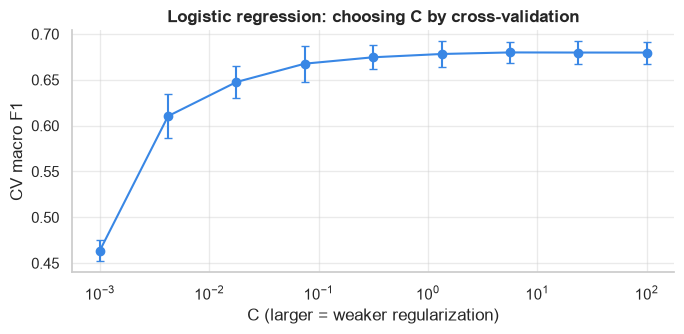

In [2]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
grid = GridSearchCV(LogisticRegression(max_iter=5000), {"C": np.logspace(-3, 2, 9)},
                    cv=cv, scoring="f1_macro", n_jobs=-1).fit(X_train, ytr)
lr = grid.best_estimator_
cvres = pd.DataFrame(grid.cv_results_)[["param_C", "mean_test_score", "std_test_score"]]
cvres.columns = ["C", "CV macro F1", "std"]
print("Best C:", grid.best_params_["C"])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(cvres["C"].astype(float), cvres["CV macro F1"], yerr=cvres["std"], marker="o", color="#3987e5", capsize=3)
ax.set_xscale("log"); ax.set_xlabel("C (larger = weaker regularization)"); ax.set_ylabel("CV macro F1")
ax.set_title("Logistic regression: choosing C by cross-validation")
plt.tight_layout(); plt.savefig(FIG / "lr_choose_C.png", dpi=120); plt.show()

This shows that very small C (strong regularization, below about 0.01) hurts: the weights are squashed so much that the model cannot separate the genres. From C ≈ 0.3 upward the score flattens out around 0.68 macro F1; cross-validation picked **C ≈ 5.6**. With 3,400 songs and only 26 features, logistic regression has little room to overfit, so weak regularization is fine.

## 2. Gaussian Naive Bayes
Naive Bayes simply measures each genre's mean and spread (a bell curve) for every feature. First we try it the obvious way, on all 26 features, and something goes wrong:

In [3]:
nb_all = GaussianNB()
print("CV accuracy, Naive Bayes on all 26 features: %.3f" % cross_val_score(nb_all, X_train, ytr, cv=cv).mean())
nb_all.fit(X_train, ytr)
v = pd.DataFrame(nb_all.var_, index=nb_all.classes_, columns=feature_names)
pd.DataFrame({"feature with the smallest spread": v.idxmin(axis=1), "its variance": v.min(axis=1)})

CV accuracy, Naive Bayes on all 26 features: 0.405


,feature with the smallest spread,its variance
classical,explicit,1.000e-09
country,instrumentalness,3.019e-02
edm,time_sig_5,1.000e-09
heavy-metal,acousticness,2.134e-02
hip-hop,instrumentalness,7.321e-02
jazz,explicit,1.003e-01


**Why it fails:** some yes/no features *never change* inside a genre: no classical training song is `explicit`, no edm song is in 5/4 time. Their bell curve has (almost) zero width, so its peak is enormous: every song that also has the "usual" value gets a gigantic likelihood for that genre, which swamps all the real musical evidence. Bell curves are a sensible model for **continuous** features (energy, tempo, …) but not for 0/1 switches.

**Fix:** Gaussian Naive Bayes uses only the **10 continuous audio features**, and its `var_smoothing` setting (a small amount added to every variance) is tuned by cross-validation. For a fair comparison we also report logistic regression on the same 10 features.

In [4]:
NB_FEATURES = data.AUDIO_FEATURES
nb_grid = GridSearchCV(GaussianNB(), {"var_smoothing": np.logspace(-9, 0, 10)}, cv=cv, scoring="f1_macro").fit(X_train[NB_FEATURES], ytr)
nb = nb_grid.best_estimator_
lr_audio = GridSearchCV(LogisticRegression(max_iter=5000), {"C": np.logspace(-3, 2, 9)}, cv=cv,
                        scoring="f1_macro", n_jobs=-1).fit(X_train[NB_FEATURES], ytr).best_estimator_
print("Best var_smoothing:", nb_grid.best_params_["var_smoothing"])
pd.DataFrame({"CV accuracy (train)": {
    "Naive Bayes, all 26 features": cross_val_score(GaussianNB(), X_train, ytr, cv=cv).mean(),
    "Naive Bayes, 10 audio features": cross_val_score(nb, X_train[NB_FEATURES], ytr, cv=cv).mean(),
    "Logistic regression, 10 audio features": cross_val_score(lr_audio, X_train[NB_FEATURES], ytr, cv=cv).mean(),
    "Logistic regression, all 26 features": cross_val_score(lr, X_train, ytr, cv=cv).mean()}}).round(3)

Best var_smoothing: 0.1


,CV accuracy (train)
"Naive Bayes, all 26 features",0.405
"Naive Bayes, 10 audio features",0.643
"Logistic regression, 10 audio features",0.699
"Logistic regression, all 26 features",0.711


This shows the fix works: Naive Bayes jumps from **40.5% to 64.3%** cross-validated accuracy when it only sees features that are actually bell-shaped-ish, with `var_smoothing = 0.1` chosen by CV. Logistic regression is better either way (69.9% on the same 10 features, 71.1% with all 26), so the comparison below is fair: the gap is not just "LR got more features".

In [5]:
print("Priors P(genre) learned from the training set:")
print(pd.Series(nb.class_prior_, index=nb.classes_).round(3).to_string())
print("\nExample: the bell curve for 'energy' in each genre (mean and std, scaled units):")
print(pd.DataFrame({"mean": nb.theta_[:, NB_FEATURES.index("energy")],
                    "std": np.sqrt(nb.var_[:, NB_FEATURES.index("energy")])}, index=nb.classes_).round(2).to_string())

Priors P(genre) learned from the training set:
classical      0.189
country        0.142
edm            0.156
heavy-metal    0.231
hip-hop        0.170
jazz           0.111

Example: the bell curve for 'energy' in each genre (mean and std, scaled units):
             mean   std
classical   -1.38  0.71
country      0.08  0.76
edm          0.49  0.53
heavy-metal  0.92  0.56
hip-hop      0.29  0.58
jazz        -0.81  0.79


This shows what Naive Bayes actually "learns": the **priors** are just the genre shares in the training set (heavy-metal 23%, jazz 11%), and for each genre and feature a bell curve. For energy, classical is centred far below average (−1.38 std), heavy-metal far above (+0.92), and the others in between. A new song's energy is compared with all six bell curves.

## 3. Test-set results: accuracy and macro F1

In [6]:
results = {}
for name, m, cols in [("Logistic regression", lr, feature_names), ("Gaussian Naive Bayes", nb, NB_FEATURES)]:
    pred = m.predict(X_test[cols])
    met = evaluate.classification_metrics(yte, pred)
    evaluate.log_score("P3 Genre Detector", name, "genre", met)
    results[name] = met
res = pd.DataFrame(results).T[["accuracy", "macro_f1", "precision", "recall"]]
res.columns = ["accuracy", "macro F1", "macro precision", "macro recall"]
res.round(3)

,accuracy,macro F1,macro precision,macro recall
Logistic regression,0.715,0.685,0.689,0.683
Gaussian Naive Bayes,0.649,0.609,0.627,0.607


This shows that **logistic regression wins clearly: 71.5% accuracy and 0.685 macro F1**, against 64.9% and 0.609 for Naive Bayes. Both are far above random guessing (18% for 6 genres). Macro F1 is a bit lower than accuracy for both models because the smaller genres (jazz, country) are harder.

In [7]:
per_genre = pd.DataFrame({
    "LR F1": pd.DataFrame(classification_report(yte, lr.predict(X_test), output_dict=True)).T.loc[GENRES, "f1-score"],
    "NB F1": pd.DataFrame(classification_report(yte, nb.predict(X_test[NB_FEATURES]), output_dict=True)).T.loc[GENRES, "f1-score"],
})
per_genre.round(3)

,LR F1,NB F1
classical,0.896,0.832
country,0.515,0.443
edm,0.587,0.548
heavy-metal,0.862,0.843
hip-hop,0.669,0.615
jazz,0.580,0.373


This shows that **classical and heavy-metal are easy** for both models (F1 0.83–0.90): they sit at the two extremes of energy and acousticness. **Country, edm and jazz are the hard ones** (F1 about 0.5–0.6 for LR). Naive Bayes struggles most with jazz (F1 0.37): jazz overlaps both classical and country, and its correlated features break the independence assumption.

## 4. Confusion matrices
Rows = true genre, columns = predicted genre. Numbers are counts of test songs.

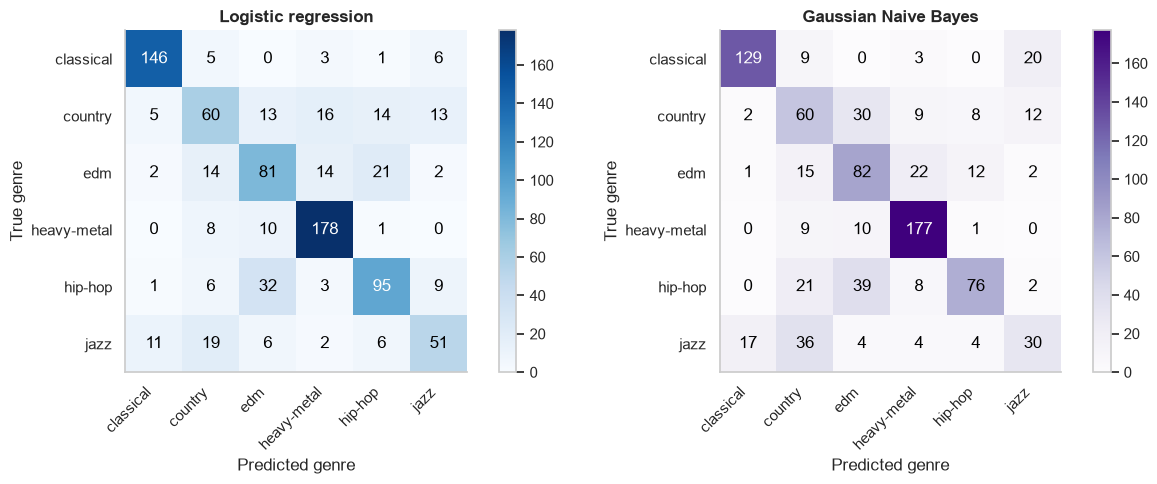

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
evaluate.plot_confusion_matrix(yte, lr.predict(X_test), GENRES, "Logistic regression", ax=axes[0])
evaluate.plot_confusion_matrix(yte, nb.predict(X_test[NB_FEATURES]), GENRES, "Gaussian Naive Bayes", ax=axes[1], cmap="Purples")
plt.tight_layout(); plt.savefig(FIG / "confusion_matrices.png", dpi=120); plt.show()
# also save each one separately for the app
evaluate.plot_confusion_matrix(yte, lr.predict(X_test), GENRES, "Logistic regression", FIG / "cm_logistic_regression.png"); plt.close()
evaluate.plot_confusion_matrix(yte, nb.predict(X_test[NB_FEATURES]), GENRES, "Gaussian Naive Bayes", FIG / "cm_naive_bayes.png", cmap="Purples"); plt.close()

In [9]:
cm = pd.crosstab(yte, lr.predict(X_test))
pairs = [(t, p, cm.loc[t, p]) for t in GENRES for p in GENRES if t != p]
print("Most common mistakes (logistic regression): true → predicted")
for t, p, n in sorted(pairs, key=lambda x: -x[2])[:5]:
    print(f"  {t:12s} → {p:12s} {n} songs")
means = data.load_all_songs()[0].groupby("track_genre")[["danceability", "energy", "acousticness", "speechiness", "valence"]].mean()
means.loc[["country", "edm", "hip-hop"]].round(2)

Most common mistakes (logistic regression): true → predicted
  hip-hop      → edm          32 songs
  edm          → hip-hop      21 songs
  jazz         → country      19 songs
  country      → heavy-metal  16 songs
  country      → hip-hop      14 songs


,danceability,energy,acousticness,speechiness,valence
track_genre,,,,,
country,0.56,0.62,0.29,0.04,0.53
edm,0.65,0.75,0.12,0.07,0.45
hip-hop,0.72,0.69,0.22,0.14,0.54


This shows the most common mistake is **hip-hop ↔ edm (32 + 21 songs)**: both are danceable (0.72 vs 0.65), energetic (0.69 vs 0.75) and electronic (low acousticness), so in "audio-feature space" they are neighbours; mostly only speechiness (rap vocals) separates them. **Jazz → country** (19) happens with mellow, acoustic jazz that sounds like a country ballad, and **country → heavy-metal / hip-hop** with loud, modern country-rock or country-rap songs. These are the same overlaps visible on P1's Song Map.

## 5. What does logistic regression look at? (weights for two genres)
Each genre has its own set of weights. A large positive weight means "a high value of this feature makes this genre more likely"; a large negative weight means the opposite. Below: the 8 biggest weights for **classical** and **heavy-metal**.

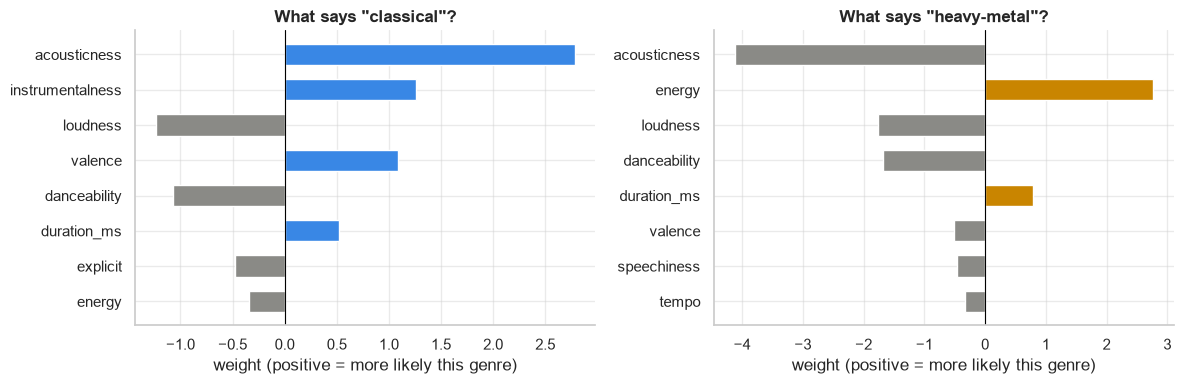

,energy,loudness,acousticness,instrumentalness,danceability,speechiness,duration_ms,valence
classical,-0.34,-1.23,2.78,1.26,-1.07,0.31,0.52,1.08
heavy-metal,2.77,-1.76,-4.12,-0.30,-1.68,-0.47,0.79,-0.51


In [10]:
W = pd.DataFrame(lr.coef_, index=lr.classes_, columns=feature_names)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, g in zip(axes, ["classical", "heavy-metal"]):
    w = W.loc[g]; top = w.abs().sort_values(ascending=False).index[:8]
    ax.barh(top, w[top], color=[GENRE_COLORS[g] if v > 0 else "#8a8a86" for v in w[top]], height=0.6)
    ax.axvline(0, color="black", lw=.8); ax.invert_yaxis(); ax.set_title(f"What says \"{g}\"?")
    ax.set_xlabel("weight (positive = more likely this genre)")
plt.tight_layout(); plt.savefig(FIG / "lr_weights.png", dpi=120); plt.show()
W.loc[["classical", "heavy-metal"], ["energy", "loudness", "acousticness", "instrumentalness", "danceability", "speechiness", "duration_ms", "valence"]].round(2)

This shows **"classical"** is signalled mainly by high **acousticness (+2.78)** and **instrumentalness (+1.26)**, and by low loudness and low danceability. **"Heavy-metal"** is signalled by high **energy (+2.77)** and very low **acousticness (−4.12)**, and low danceability. One surprise: loudness has a *negative* weight for heavy-metal. Energy and loudness are strongly correlated (0.85), so the model gives most of the credit to energy; *given the same energy*, extra loudness points slightly more to edm/hip-hop (heavily mastered tracks). Weights of correlated features must be read together, not one at a time.

## 6. Is the "naive" assumption true for our data?
Naive Bayes assumes features are independent *within each genre*. Let's measure the correlation of some feature pairs inside each genre.

In [11]:
songs, X_all = data.load_all_songs()
tr_songs = songs[songs.split == "train"]
pairs = [("energy", "loudness"), ("energy", "acousticness"), ("danceability", "valence")]
indep = pd.DataFrame({f"{a} vs {b}": tr_songs.groupby("track_genre").apply(lambda d: d[a].corr(d[b]), include_groups=False)
                      for a, b in pairs})
indep.round(2)

,energy vs loudness,energy vs acousticness,danceability vs valence
track_genre,,,
classical,0.80,-0.60,0.55
country,0.73,-0.75,0.46
edm,0.60,-0.34,0.39
heavy-metal,0.64,-0.44,0.21
hip-hop,0.67,-0.26,0.31
jazz,0.75,-0.70,0.51


This shows the independence assumption is clearly **false**: within every genre, energy and loudness are strongly correlated (0.60–0.80), and energy and acousticness strongly negatively correlated. Naive Bayes therefore "double counts" the same evidence (loud *and* energetic *and* not acoustic counted as three independent clues), which makes it over-confident and less accurate. Logistic regression learns weights jointly and can split credit between correlated features.

## 7. Generative vs discriminative: does Naive Bayes win with little data?
Theory says generative models learn faster from few examples. We train both models on growing random subsets of the training set and measure 5-fold cross-validated accuracy (training set only).

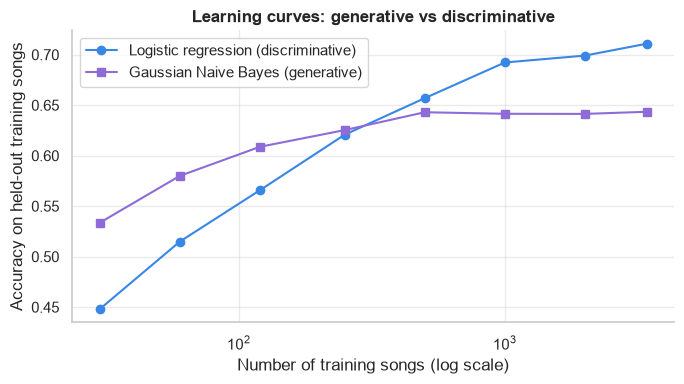

,Logistic regression,Gaussian Naive Bayes
training songs,,
30,0.448,0.534
60,0.515,0.580
120,0.566,0.609
250,0.621,0.625
500,0.657,0.643
1000,0.692,0.641
2000,0.699,0.641
3413,0.711,0.643


In [12]:
sizes = [30, 60, 120, 250, 500, 1000, 2000, len(X_train)]
rng = np.random.default_rng(42)
curve = []
for n in sizes:
    accs = {"Logistic regression": [], "Gaussian Naive Bayes": []}
    for rep in range(5):
        idx = rng.choice(len(X_train), n, replace=False)
        ys = ytr.iloc[idx]
        # evaluate on the rest of the training set (never the test set)
        rest = np.setdiff1d(np.arange(len(X_train)), idx)
        if len(rest) < 200: rest = idx  # full-size point: fall back to CV below
        for name, m, cols in [("Logistic regression", LogisticRegression(C=grid.best_params_["C"], max_iter=5000), feature_names),
                              ("Gaussian Naive Bayes", GaussianNB(var_smoothing=nb.var_smoothing), NB_FEATURES)]:
            if n == len(X_train):
                accs[name].append(cross_val_score(m, X_train[cols], ytr, cv=cv).mean())
            else:
                accs[name].append(m.fit(X_train[cols].iloc[idx], ys).score(X_train[cols].iloc[rest], ytr.iloc[rest]))
    curve.append({"training songs": n, **{k: np.mean(v) for k, v in accs.items()}})
curve = pd.DataFrame(curve).set_index("training songs")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curve.index, curve["Logistic regression"], marker="o", color="#3987e5", label="Logistic regression (discriminative)")
ax.plot(curve.index, curve["Gaussian Naive Bayes"], marker="s", color="#8e6cd8", label="Gaussian Naive Bayes (generative)")
ax.set_xscale("log"); ax.set_xlabel("Number of training songs (log scale)"); ax.set_ylabel("Accuracy on held-out training songs")
ax.set_title("Learning curves: generative vs discriminative"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "learning_curves.png", dpi=120); plt.show()
curve.round(3)

This shows exactly what theory predicts. With **very few training songs (30–120), Naive Bayes is better** (e.g. 53% vs 45% with 30 songs): it only has to estimate a mean and a spread per feature, so it learns fast. Around 250 songs they are level, and **with more data logistic regression keeps improving while Naive Bayes plateaus at about 64%**, because its wrong independence assumption limits it no matter how much data it gets.

## 8. Save both models (the app shows both side by side)

In [13]:
joblib.dump({"model": lr, "name": "Logistic regression", "features": feature_names}, MODELS / "logistic_regression.joblib")
joblib.dump({"model": nb, "name": "Gaussian Naive Bayes", "features": NB_FEATURES}, MODELS / "naive_bayes.joblib")
print("Saved:", sorted(p.name for p in MODELS.iterdir()))

Saved: ['logistic_regression.joblib', 'naive_bayes.joblib']


## Verdict

**Logistic regression wins** (71.5% accuracy, 0.685 macro F1 vs 64.9% and 0.609). This fits generative vs discriminative theory: with ~3,400 training songs we have plenty of data, and our features are strongly correlated within each genre, so the discriminative model, which learns the genre boundaries directly without assuming independence, does better. Naive Bayes is the faster learner when data is scarce (it wins below ~250 songs) but its "naive" assumption caps its accuracy. Both models confuse the same musically similar genres (hip-hop ↔ edm, jazz ↔ country), which tells us those overlaps are in the data itself, not in one model.

## Results summary

| Model | Features | Accuracy | Macro F1 |
|---|---|---|---|
| Logistic regression (C ≈ 5.6) | all 26 | **0.715** | **0.685** |
| Gaussian Naive Bayes (var_smoothing = 0.1) | 10 audio | 0.649 | 0.609 |
| *Random guess (baseline)* | | *0.180* | *0.178* |

**Takeaways**
- Logistic regression (discriminative) beats Naive Bayes (generative) by about 7 points; both are far above guessing.
- Classical and heavy-metal are easy; **hip-hop ↔ edm** is the biggest confusion (both danceable, energetic, electronic).
- The "naive" independence assumption is false here (energy and loudness correlate 0.6–0.8 within genres).
- Naive Bayes wins when data is scarce (below ~250 songs), exactly as theory says.
- Gaussian NB needs continuous features: on 0/1 columns that never vary in a genre it collapsed to 40%.

## Questions you may be asked

**1. Why is Naive Bayes called "naive"? Is the assumption true for our features?**
Because it assumes that, once you know the genre, all features are independent of each other, so it can multiply one bell curve per feature. For our data this is false: within each genre energy and loudness correlate 0.60–0.80, and energy and acousticness −0.26 to −0.75 (section 6). NB therefore counts the same evidence several times. It still works reasonably (65%) because classification only needs the right genre to come out on top, not perfect probabilities.

**2. When can Naive Bayes beat logistic regression?**
When training data is scarce (it only needs a mean and spread per feature per genre, so it learns fast: see section 7), when its independence assumption is roughly true, or when there are very many features relative to examples (e.g. text classification). With plenty of data and correlated features, logistic regression usually wins, as it did here.

**3. What does softmax do?**
It turns the 6 raw genre scores (any real numbers) into 6 probabilities between 0 and 1 that add up to 1, by exponentiating each score and dividing by the total. The genre with the highest score gets the highest probability, and bigger gaps between scores give more confident probabilities.

**4. Why macro F1 instead of only accuracy?**
Accuracy is dominated by big genres: heavy-metal is 23% of songs, jazz only 11%. A model could ignore jazz completely and still have decent accuracy. Macro F1 computes F1 for each genre separately and averages them, so doing badly on a small genre hurts the score as much as on a big one. F1 also balances precision and recall.

**5. What does one off-diagonal cell in the confusion matrix mean?**
It counts test songs of one true genre (the row) that the model predicted as another genre (the column). For example, the logistic-regression cell at row "hip-hop", column "edm" is 32: 32 real hip-hop songs were labelled edm. Large off-diagonal cells show which genres the model confuses, here genres that are close in feature space.